In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('/content/dynamic_demand_forecasting_dataset.csv')
df

,Record_Date,Product_ID,Product_Name,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,...,Revenue,Cost_Of_Goods_Sold,Profit,Customer_Rating,Review_Text,Sentiment_Label,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,2024-01-01,P101,Rice,Staples,SUP01,62.0,48.0,0,0,1,...,2170.0,1680.0,490.0,1.0,This Rice did not feel worth the price. I may ...,Negative,NaN,NaN,NaN,NaN
1,2024-01-01,P102,Milk,Dairy,SUP02,32.0,23.0,5,0,1,...,1672.0,1265.0,407.0,3.0,Average experience with this Milk.,Neutral,NaN,NaN,NaN,NaN
2,2024-01-01,P103,Biscuits,Snacks,SUP03,15.0,9.0,0,0,1,...,705.0,423.0,282.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-01,P104,Cooking Oil,Cooking Essentials,SUP04,145.0,118.0,0,0,1,...,2755.0,2242.0,513.0,5.0,Very satisfied with this Cooking Oil; the qual...,Positive,NaN,NaN,NaN,NaN
4,2024-01-01,P105,Wheat Flour,Staples,SUP01,48.0,37.0,0,0,1,...,1104.0,851.0,253.0,4.0,Wheat Flour is good for daily use and I would ...,Positive,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8767,2025-12-31,P108,Shampoo,Personal Care,SUP04,95.0,66.0,0,0,0,...,1045.0,726.0,319.0,4.0,Shampoo is good for daily use and I would buy ...,Positive,11.0,14.0,12.29,11.43
8768,2025-12-31,P109,Soap,Personal Care,SUP05,38.0,24.0,25,1,0,...,769.5,648.0,121.5,4.0,Very satisfied with this Soap; the quality fee...,Positive,28.0,21.0,22.29,21.80
8769,2025-12-31,P110,Coffee,Beverages,SUP03,160.0,122.0,0,0,0,...,1280.0,976.0,304.0,4.0,Coffee is worth the price and arrived in good ...,Positive,11.0,11.0,10.29,10.13
8770,2025-12-31,P111,Sugar,Staples,SUP01,46.0,34.0,0,0,0,...,920.0,680.0,240.0,4.0,I like this Sugar. It meets my expectations an...,Positive,26.0,30.0,27.29,23.77


In [4]:
df.head()

,Record_Date,Product_ID,Product_Name,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,...,Revenue,Cost_Of_Goods_Sold,Profit,Customer_Rating,Review_Text,Sentiment_Label,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,2024-01-01,P101,Rice,Staples,SUP01,62.0,48.0,0,0,1,...,2170.0,1680.0,490.0,1.0,This Rice did not feel worth the price. I may ...,Negative,NaN,NaN,NaN,NaN
1,2024-01-01,P102,Milk,Dairy,SUP02,32.0,23.0,5,0,1,...,1672.0,1265.0,407.0,3.0,Average experience with this Milk.,Neutral,NaN,NaN,NaN,NaN
2,2024-01-01,P103,Biscuits,Snacks,SUP03,15.0,9.0,0,0,1,...,705.0,423.0,282.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-01,P104,Cooking Oil,Cooking Essentials,SUP04,145.0,118.0,0,0,1,...,2755.0,2242.0,513.0,5.0,Very satisfied with this Cooking Oil; the qual...,Positive,NaN,NaN,NaN,NaN
4,2024-01-01,P105,Wheat Flour,Staples,SUP01,48.0,37.0,0,0,1,...,1104.0,851.0,253.0,4.0,Wheat Flour is good for daily use and I would ...,Positive,NaN,NaN,NaN,NaN


In [5]:
df.tail()

,Record_Date,Product_ID,Product_Name,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,...,Revenue,Cost_Of_Goods_Sold,Profit,Customer_Rating,Review_Text,Sentiment_Label,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
8767,2025-12-31,P108,Shampoo,Personal Care,SUP04,95.0,66.0,0,0,0,...,1045.0,726.0,319.0,4.0,Shampoo is good for daily use and I would buy ...,Positive,11.0,14.0,12.29,11.43
8768,2025-12-31,P109,Soap,Personal Care,SUP05,38.0,24.0,25,1,0,...,769.5,648.0,121.5,4.0,Very satisfied with this Soap; the quality fee...,Positive,28.0,21.0,22.29,21.80
8769,2025-12-31,P110,Coffee,Beverages,SUP03,160.0,122.0,0,0,0,...,1280.0,976.0,304.0,4.0,Coffee is worth the price and arrived in good ...,Positive,11.0,11.0,10.29,10.13
8770,2025-12-31,P111,Sugar,Staples,SUP01,46.0,34.0,0,0,0,...,920.0,680.0,240.0,4.0,I like this Sugar. It meets my expectations an...,Positive,26.0,30.0,27.29,23.77
8771,2025-12-31,P112,Detergent,Household,SUP05,110.0,78.0,0,0,0,...,1430.0,1014.0,416.0,5.0,Detergent is good for daily use and I would bu...,Positive,13.0,9.0,13.86,13.67


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8772 entries, 0 to 8771
Data columns (total 45 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Record_Date                8772 non-null   object 
 1   Product_ID                 8772 non-null   object 
 2   Product_Name               8772 non-null   object 
 3   Category                   8772 non-null   object 
 4   Supplier_ID                8772 non-null   object 
 5   Unit_Price                 8772 non-null   float64
 6   Unit_Cost                  8772 non-null   float64
 7   Discount_Percent           8772 non-null   int64  
 8   Promotion                  8772 non-null   int64  
 9   Holiday                    8772 non-null   int64  
 10  Day_Of_Week                8772 non-null   object 
 11  Day_Of_Week_Num            8772 non-null   int64  
 12  Month                      8772 non-null   int64  
 13  Quarter                    8772 non-null   int64

In [7]:
df.describe(include="all")

,Record_Date,Product_ID,Product_Name,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,...,Revenue,Cost_Of_Goods_Sold,Profit,Customer_Rating,Review_Text,Sentiment_Label,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
count,8772,8772,8772,8772,8772,8772.000000,8772.000000,8772.000000,8772.000000,8772.000000,...,8772.000000,8772.000000,8772.000000,7741.000000,7741,7741,8760.000000,8688.000000,8688.000000,8412.000000
unique,731,12,12,8,5,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,168,3,NaN,NaN,NaN,NaN
top,2024-01-01,P101,Rice,Staples,SUP01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,I like this Wheat Flour. It meets my expectati...,Positive,NaN,NaN,NaN,NaN
freq,12,731,731,2193,2193,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,102,5096,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,73.166667,54.416667,1.284200,0.073529,0.019152,...,1159.905181,873.307912,286.597270,3.768505,NaN,NaN,22.148516,22.111878,22.133263,22.077636
std,NaN,NaN,NaN,NaN,NaN,49.090871,38.380694,4.443857,0.261018,0.137066,...,583.550712,488.555250,124.215375,1.191440,NaN,NaN,12.420119,12.400010,11.458175,11.311578
min,NaN,NaN,NaN,NaN,NaN,7.000000,5.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-268.250000,1.000000,NaN,NaN,0.000000,0.000000,5.710000,7.230000
25%,NaN,NaN,NaN,NaN,NaN,36.500000,23.750000,0.000000,0.000000,0.000000,...,751.800000,510.000000,210.000000,3.000000,NaN,NaN,12.000000,12.000000,12.000000,11.970000
50%,NaN,NaN,NaN,NaN,NaN,55.000000,42.500000,0.000000,0.000000,0.000000,...,1140.000000,854.000000,290.000000,4.000000,NaN,NaN,19.000000,19.000000,20.290000,20.300000
75%,NaN,NaN,NaN,NaN,NaN,112.500000,80.750000,0.000000,0.000000,0.000000,...,1524.000000,1152.000000,378.000000,5.000000,NaN,NaN,30.000000,30.000000,29.430000,29.307500


In [8]:
df.isna().sum()

,0
Record_Date,0
Product_ID,0
Product_Name,0
Category,0
Supplier_ID,0
Unit_Price,0
Unit_Cost,0
Discount_Percent,0
Promotion,0
Holiday,0


In [9]:
models=df.select_dtypes(include=object).columns
models

Index(['Record_Date', 'Product_ID', 'Product_Name', 'Category', 'Supplier_ID',
       'Day_Of_Week', 'Season', 'Review_Customer_ID', 'Customer_Gender',
       'Customer_Segment', 'Review_Region', 'Review_Text', 'Sentiment_Label'],
      dtype='object')

In [10]:
for i in models:
  print(i,df[i].nunique())
  print("__"*40)

Record_Date 731
________________________________________________________________________________
Product_ID 12
________________________________________________________________________________
Product_Name 12
________________________________________________________________________________
Category 8
________________________________________________________________________________
Supplier_ID 5
________________________________________________________________________________
Day_Of_Week 7
________________________________________________________________________________
Season 4
________________________________________________________________________________
Review_Customer_ID 600
________________________________________________________________________________
Customer_Gender 4
________________________________________________________________________________
Customer_Segment 4
________________________________________________________________________________
Review_Region 5
____________________

In [11]:
df["Record_Date"]=pd.to_datetime(df["Record_Date"])
df=df.sort_values(["Product_ID","Record_Date"]).reset_index(drop=True)
print(df.duplicated(["Record_Date","Product_ID"]).sum())

0


In [12]:
df.shape

(8772, 45)

In [13]:
print(df["Record_Date"].min(), "-", df["Record_Date"].max())

2024-01-01 00:00:00 - 2025-12-31 00:00:00


In [14]:
df.isna().sum()

,0
Record_Date,0
Product_ID,0
Product_Name,0
Category,0
Supplier_ID,0
Unit_Price,0
Unit_Cost,0
Discount_Percent,0
Promotion,0
Holiday,0


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
review_cols=["Review_Customer_ID", "Customer_Age", "Customer_Gender", "Customer_Segment", "Review_Region", "Customer_Rating", "Review_Text", "Sentiment_Label"]
df=df.drop(columns=review_cols)
df

,Record_Date,Product_ID,Product_Name,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,...,Reorder_Quantity,Stockout_Flag,Stockout_Risk_Next_7_Days,Revenue,Cost_Of_Goods_Sold,Profit,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,2024-01-01,P101,Rice,Staples,SUP01,62.0,48.0,0,0,1,...,0,0,1.0,2170.0,1680.0,490.0,NaN,NaN,NaN,NaN
1,2024-01-02,P101,Rice,Staples,SUP01,62.0,48.0,0,0,0,...,0,0,1.0,1488.0,1152.0,336.0,35.0,NaN,NaN,NaN
2,2024-01-03,P101,Rice,Staples,SUP01,62.0,48.0,0,0,0,...,159,0,0.0,1550.0,1200.0,350.0,24.0,NaN,NaN,NaN
3,2024-01-04,P101,Rice,Staples,SUP01,62.0,48.0,0,0,0,...,0,0,0.0,1860.0,1440.0,420.0,25.0,NaN,NaN,NaN
4,2024-01-05,P101,Rice,Staples,SUP01,62.0,48.0,0,0,0,...,0,0,0.0,1674.0,1296.0,378.0,30.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8767,2025-12-27,P112,Detergent,Household,SUP05,110.0,78.0,0,0,0,...,83,0,NaN,1650.0,1170.0,480.0,12.0,14.0,13.43,13.57
8768,2025-12-28,P112,Detergent,Household,SUP05,110.0,78.0,0,0,0,...,0,0,NaN,1540.0,1092.0,448.0,15.0,12.0,13.57,13.60
8769,2025-12-29,P112,Detergent,Household,SUP05,110.0,78.0,0,0,0,...,0,0,NaN,1650.0,1170.0,480.0,14.0,17.0,13.86,13.57
8770,2025-12-30,P112,Detergent,Household,SUP05,110.0,78.0,0,0,0,...,0,0,NaN,1430.0,1014.0,416.0,15.0,11.0,13.57,13.70


In [17]:
lag_cols = ["Sales_Lag_1", "Sales_Lag_7", "Sales_Rolling_7_Avg", "Sales_Rolling_30_Avg"]
df[lag_cols] = df.groupby("Product_ID")[lag_cols].bfill().fillna(0)

In [18]:
df = df.dropna(subset=["Stockout_Risk_Next_7_Days"]).reset_index(drop=True)
df["Stockout_Risk_Next_7_Days"] = df["Stockout_Risk_Next_7_Days"].astype(int)

In [19]:
df = df.drop(columns=["Product_Name", "Day_Of_Week"])

In [20]:
df.isna().sum()

,0
Record_Date,0
Product_ID,0
Category,0
Supplier_ID,0
Unit_Price,0
Unit_Cost,0
Discount_Percent,0
Promotion,0
Holiday,0
Day_Of_Week_Num,0


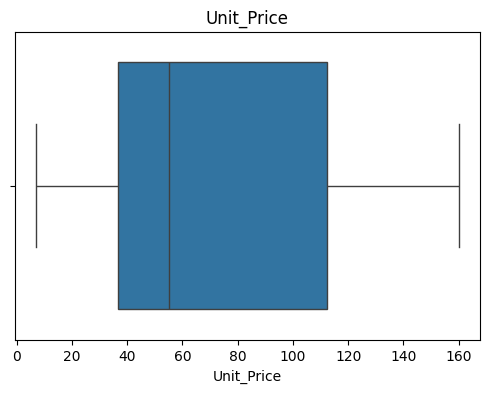

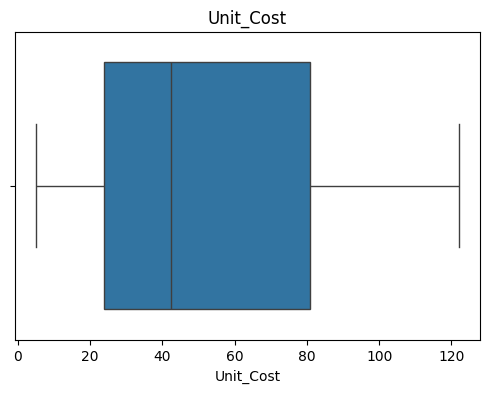

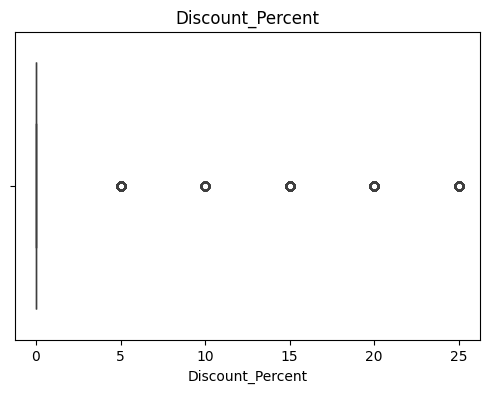

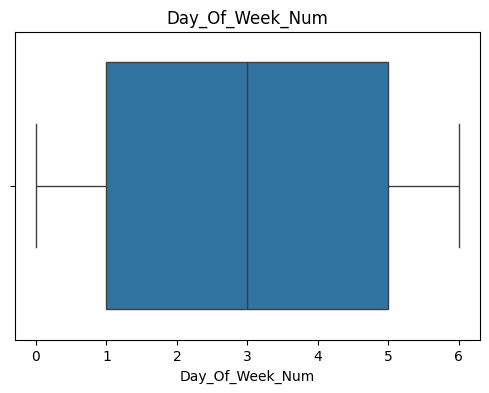

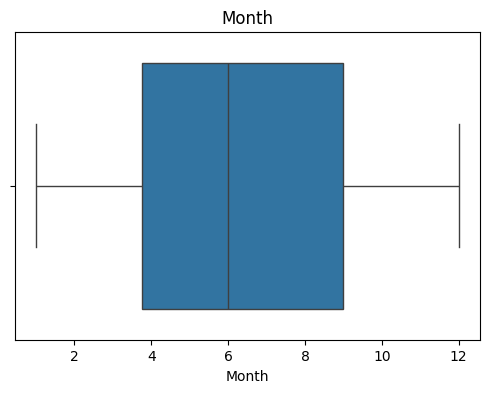

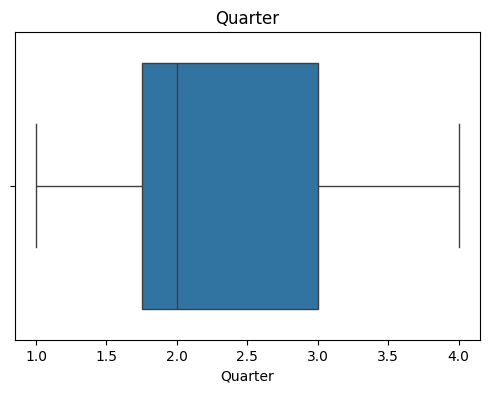

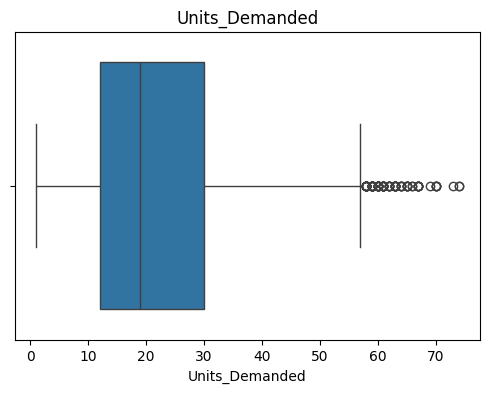

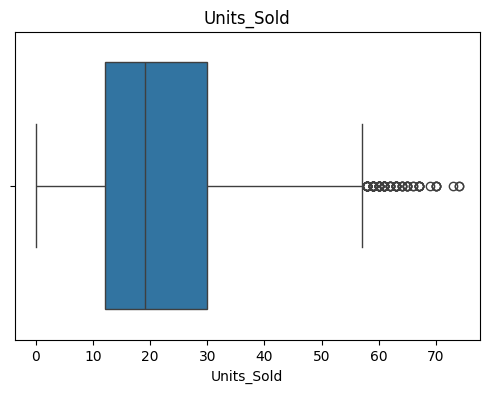

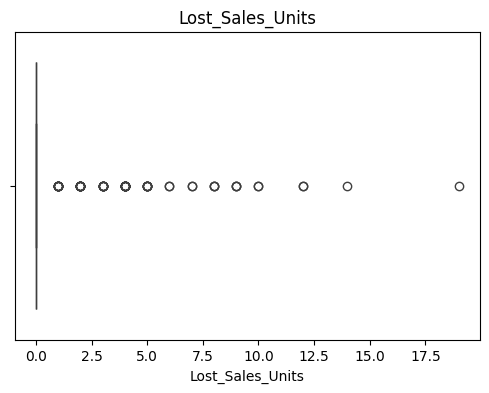

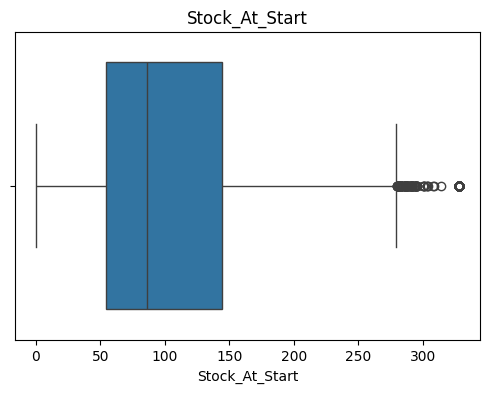

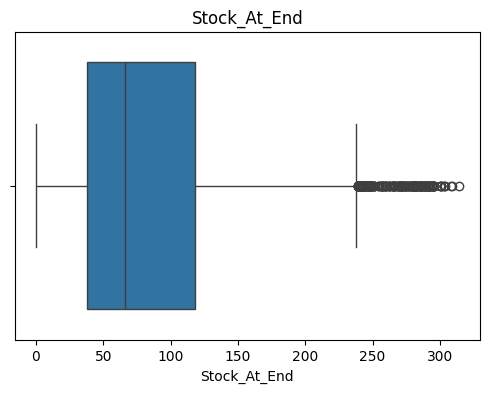

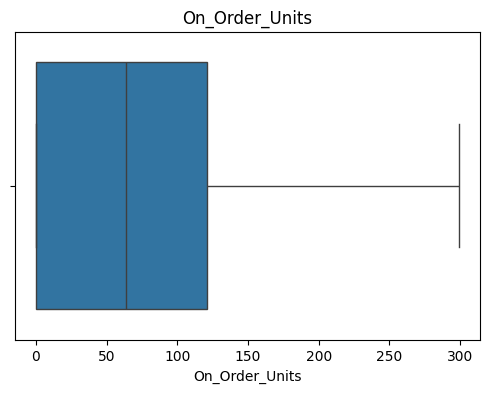

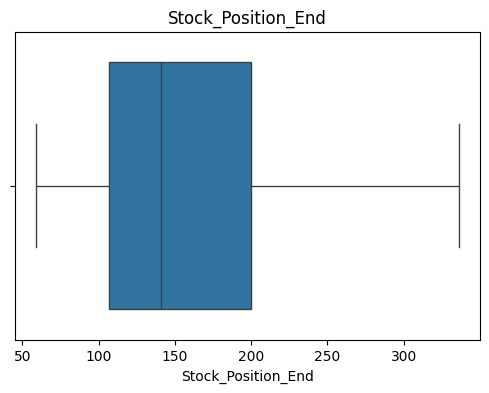

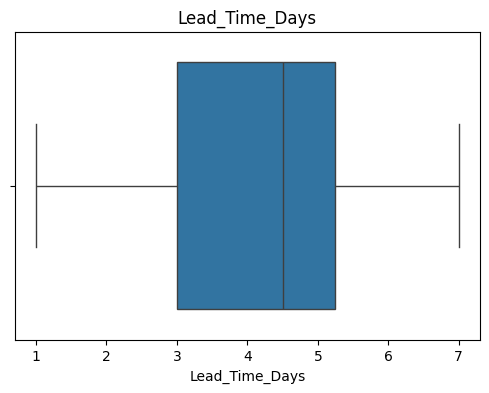

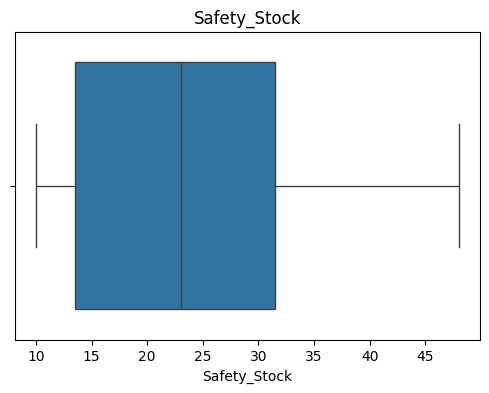

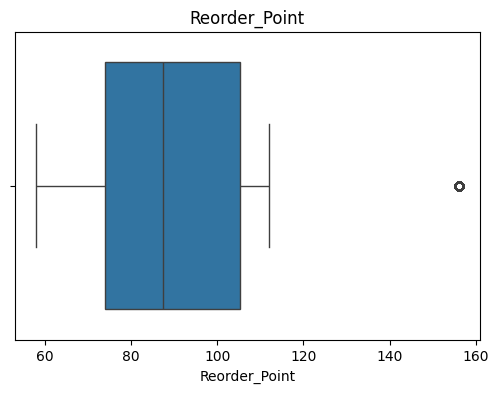

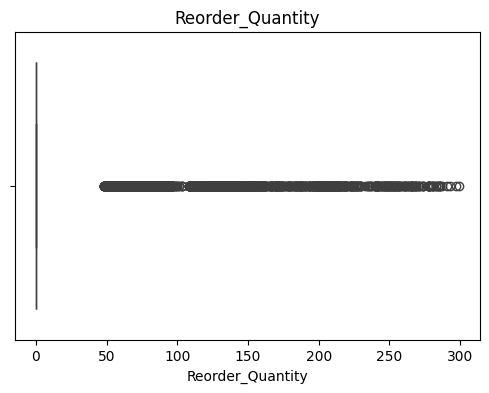

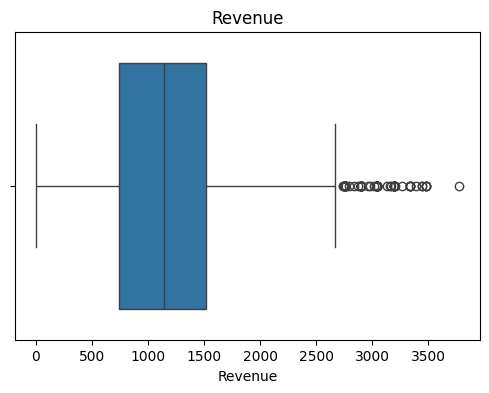

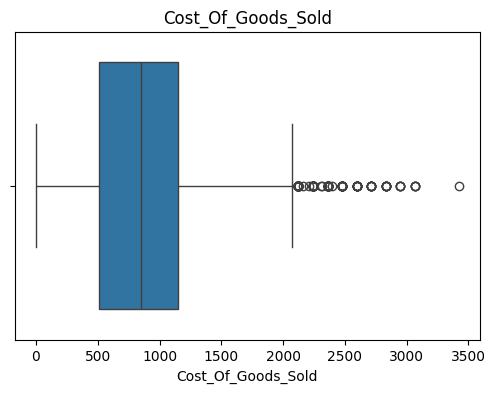

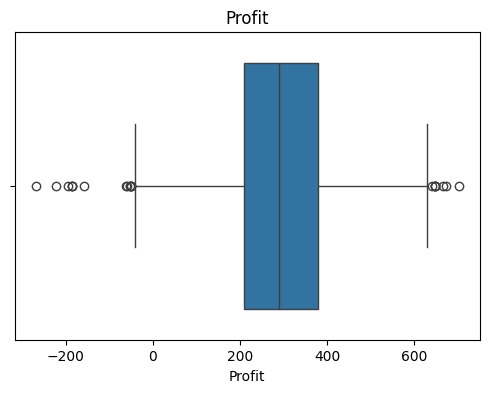

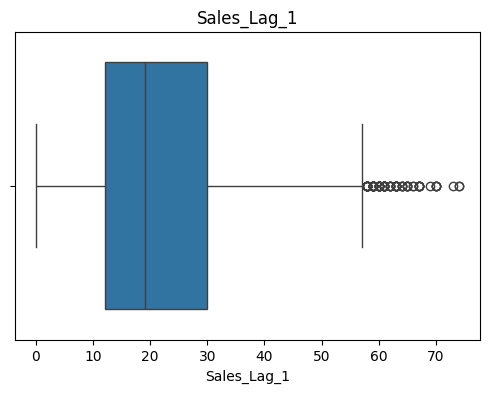

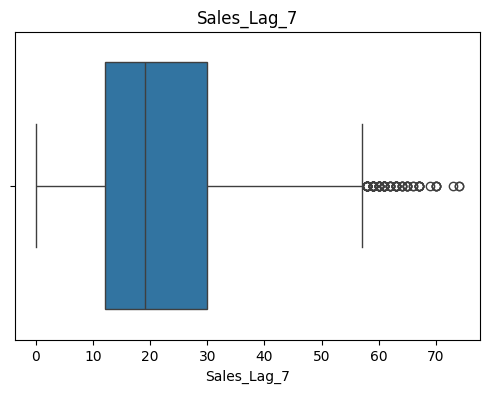

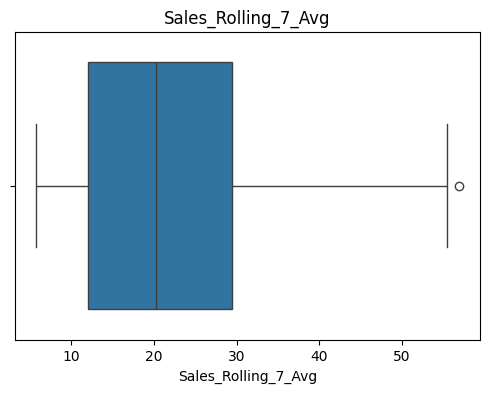

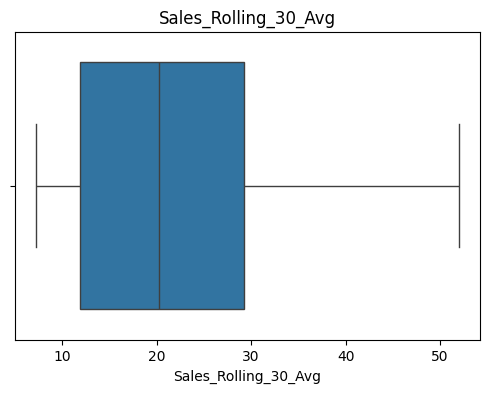

In [21]:
num_cols=[c for c in df.select_dtypes(include="number").columns if df[c].nunique()>2]
for col in num_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])
  plt.title(col)
  plt.show()

In [22]:
print("Share of days with a stockout:",df.Stockout_Flag.mean().round(3))
print("Demand lost to stockouts:",df.Lost_Sales_Units.sum(),"of",df.Units_Demanded.sum())

Share of days with a stockout: 0.008
Demand lost to stockouts: 301 of 192409


In [23]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for i in ["Product_ID","Supplier_ID","Category","Season"]:
  df[i]=le.fit_transform(df[i].astype(str))
df.head()

,Record_Date,Product_ID,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,Day_Of_Week_Num,...,Reorder_Quantity,Stockout_Flag,Stockout_Risk_Next_7_Days,Revenue,Cost_Of_Goods_Sold,Profit,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,2024-01-01,0,7,0,62.0,48.0,0,0,1,0,...,0,0,1,2170.0,1680.0,490.0,35.0,35.0,28.57,28.93
1,2024-01-02,0,7,0,62.0,48.0,0,0,0,1,...,0,0,1,1488.0,1152.0,336.0,35.0,35.0,28.57,28.93
2,2024-01-03,0,7,0,62.0,48.0,0,0,0,2,...,159,0,0,1550.0,1200.0,350.0,24.0,35.0,28.57,28.93
3,2024-01-04,0,7,0,62.0,48.0,0,0,0,3,...,0,0,0,1860.0,1440.0,420.0,25.0,35.0,28.57,28.93
4,2024-01-05,0,7,0,62.0,48.0,0,0,0,4,...,0,0,0,1674.0,1296.0,378.0,30.0,35.0,28.57,28.93


In [24]:
df.corr(numeric_only=True).Stockout_Risk_Next_7_Days.sort_values()

,Stockout_Risk_Next_7_Days
On_Order_Units,-0.438303
Lead_Time_Days,-0.430588
Unit_Price,-0.306739
Supplier_ID,-0.306428
Unit_Cost,-0.288887
Reorder_Recommended,-0.264310
Product_ID,-0.233657
Reorder_Quantity,-0.216585
Stock_Position_End,-0.084660
Season,-0.065287


In [25]:
df1=df.drop(["Revenue","Cost_Of_Goods_Sold","Profit","Units_Sold","Lost_Sales_Units"],axis=1)
df1=df1.sort_values("Record_Date").reset_index(drop=True)
df1

,Record_Date,Product_ID,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,Day_Of_Week_Num,...,Safety_Stock,Reorder_Point,Reorder_Recommended,Reorder_Quantity,Stockout_Flag,Stockout_Risk_Next_7_Days,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,2024-01-01,0,7,0,62.0,48.0,0,0,1,0,...,30,105,0,0,0,1,35.0,35.0,28.57,28.93
1,2024-01-01,4,7,0,48.0,37.0,0,0,1,0,...,24,84,0,0,0,1,23.0,23.0,23.43,24.03
2,2024-01-01,11,4,4,110.0,78.0,0,0,1,0,...,14,74,0,0,0,0,18.0,18.0,12.43,11.53
3,2024-01-01,6,0,2,120.0,89.0,0,0,1,0,...,12,72,0,0,0,0,13.0,13.0,12.00,11.53
4,2024-01-01,3,1,3,145.0,118.0,0,0,1,0,...,17,87,0,0,0,1,19.0,19.0,17.29,17.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8683,2025-12-24,2,6,2,15.0,9.0,0,0,0,2,...,36,156,0,0,0,1,37.0,31.0,37.43,36.83
8684,2025-12-24,1,2,1,32.0,23.0,0,0,0,2,...,48,88,0,0,0,1,48.0,45.0,50.29,49.33
8685,2025-12-24,0,7,0,62.0,48.0,0,0,0,2,...,30,105,0,0,0,1,37.0,36.0,34.71,31.17
8686,2025-12-24,10,7,0,46.0,34.0,10,1,0,2,...,26,92,0,0,0,1,24.0,23.0,23.00,22.90


In [26]:
x=df1.drop(["Stockout_Risk_Next_7_Days","Record_Date"],axis=1)
x

,Product_ID,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,Day_Of_Week_Num,Month,...,Lead_Time_Days,Safety_Stock,Reorder_Point,Reorder_Recommended,Reorder_Quantity,Stockout_Flag,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,0,7,0,62.0,48.0,0,0,1,0,1,...,3,30,105,0,0,0,35.0,35.0,28.57,28.93
1,4,7,0,48.0,37.0,0,0,1,0,1,...,3,24,84,0,0,0,23.0,23.0,23.43,24.03
2,11,4,4,110.0,78.0,0,0,1,0,1,...,5,14,74,0,0,0,18.0,18.0,12.43,11.53
3,6,0,2,120.0,89.0,0,0,1,0,1,...,6,12,72,0,0,0,13.0,13.0,12.00,11.53
4,3,1,3,145.0,118.0,0,0,1,0,1,...,5,17,87,0,0,0,19.0,19.0,17.29,17.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8683,2,6,2,15.0,9.0,0,0,0,2,12,...,4,36,156,0,0,0,37.0,31.0,37.43,36.83
8684,1,2,1,32.0,23.0,0,0,0,2,12,...,1,48,88,0,0,0,48.0,45.0,50.29,49.33
8685,0,7,0,62.0,48.0,0,0,0,2,12,...,3,30,105,0,0,0,37.0,36.0,34.71,31.17
8686,10,7,0,46.0,34.0,10,1,0,2,12,...,3,26,92,0,0,0,24.0,23.0,23.00,22.90


In [27]:
y=df1["Stockout_Risk_Next_7_Days"]
y

,Stockout_Risk_Next_7_Days
0,1
1,1
2,0
3,0
4,1
...,...
8683,1
8684,1
8685,1
8686,1


In [28]:
y.value_counts()

,count
Stockout_Risk_Next_7_Days,
0,5297
1,3391


In [29]:
cut=df1["Record_Date"].quantile(0.70)
xtrain,xtest=x[df1["Record_Date"]<=cut],x[df1["Record_Date"]>cut]
ytrain,ytest=y[df1["Record_Date"]<=cut],y[df1["Record_Date"]>cut]

time based split: first 70% of dates = train, last 30% = test (no shuffling for time series)


In [30]:
xtrain.shape

(6084, 28)

In [31]:
xtest.shape

(2604, 28)

In [32]:
ytrain.value_counts()

,count
Stockout_Risk_Next_7_Days,
0,3776
1,2308


In [33]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=100)
xtrain1,ytrain1=smote.fit_resample(xtrain,ytrain)

In [34]:
ytrain1.value_counts()

,count
Stockout_Risk_Next_7_Days,
1,3776
0,3776


In [35]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
xtrain1=scaler.fit_transform(xtrain1)
xtest=scaler.transform(xtest)

In [36]:
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay,classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [37]:
knn=KNeighborsClassifier(n_neighbors=7)
dt=DecisionTreeClassifier(max_depth=5)
nb=GaussianNB()
rf=RandomForestClassifier()
lr=LogisticRegression()


models=[knn,dt,nb,rf,lr]

KNeighborsClassifier(n_neighbors=7)
accuracy_score=  0.8214285714285714
confusion_matrix [[1241  280]
 [ 185  898]]
classification_report               precision    recall  f1-score   support

           0       0.87      0.82      0.84      1521
           1       0.76      0.83      0.79      1083

    accuracy                           0.82      2604
   macro avg       0.82      0.82      0.82      2604
weighted avg       0.83      0.82      0.82      2604

____________________________________________________________________________________________________
DecisionTreeClassifier(max_depth=5)
accuracy_score=  0.8552227342549923
confusion_matrix [[1327  194]
 [ 183  900]]
classification_report               precision    recall  f1-score   support

           0       0.88      0.87      0.88      1521
           1       0.82      0.83      0.83      1083

    accuracy                           0.86      2604
   macro avg       0.85      0.85      0.85      2604
weighted avg       0.86 

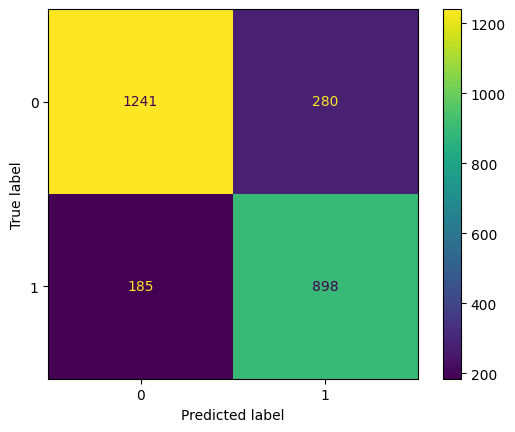

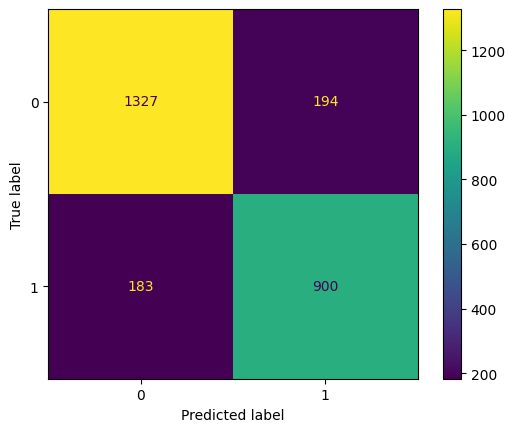

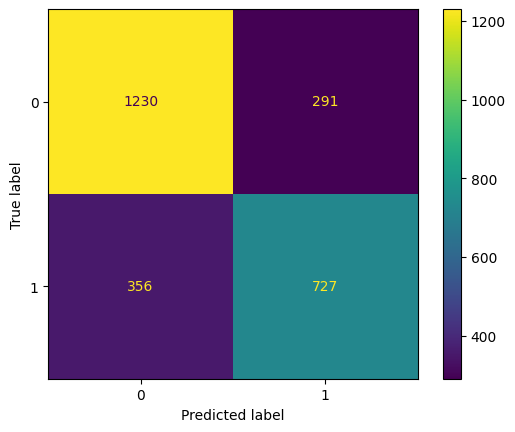

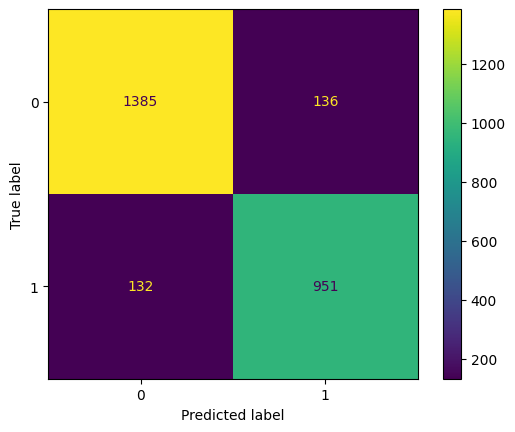

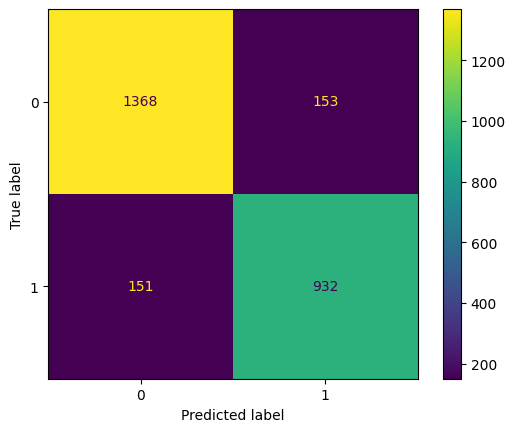

In [38]:
for i in models:
  print(i)
  i.fit(xtrain1,ytrain1)
  ypred=i.predict(xtest)
  print(f"accuracy_score= ",accuracy_score(ytest,ypred))
  print(f"confusion_matrix",confusion_matrix(ytest,ypred))
  cm=confusion_matrix(ytest,ypred)
  cmd=ConfusionMatrixDisplay(cm)
  print(cmd.plot())
  print(f"classification_report",classification_report(ytest,ypred))
  print("__"*50)


In [39]:
from sklearn.model_selection import GridSearchCV
modelcv=RandomForestClassifier()
help(modelcv)

Help on RandomForestClassifier in module sklearn.ensemble._forest object:

class RandomForestClassifier(ForestClassifier)
 |  RandomForestClassifier(
 |      n_estimators=100,
 |      *,
 |      criterion='gini',
 |      max_depth=None,
 |      min_samples_split=2,
 |      min_samples_leaf=1,
 |      min_weight_fraction_leaf=0.0,
 |      max_features='sqrt',
 |      max_leaf_nodes=None,
 |      min_impurity_decrease=0.0,
 |      bootstrap=True,
 |      oob_score=False,
 |      n_jobs=None,
 |      random_state=None,
 |      verbose=0,
 |      warm_start=False,
 |      class_weight=None,
 |      ccp_alpha=0.0,
 |      max_samples=None,
 |      monotonic_cst=None
 |  )
 |
 |  A random forest classifier.
 |
 |  A random forest is a meta estimator that fits a number of decision tree
 |  classifiers on various sub-samples of the dataset and uses averaging to
 |  improve the predictive accuracy and control over-fitting.
 |  Trees in the forest use the best split strategy, i.e. equivalent to 

In [40]:
parameter={'n_estimators':[75],
           'criterion':['gini','entropy','log_loss'],
           'max_depth':[2],
           'min_samples_split':[2]}

cv=GridSearchCV(modelcv,
                parameter,
                cv=10,
                scoring='accuracy')
cv.fit(xtrain1,ytrain1)
cv.best_params_

{'criterion': 'entropy',
 'max_depth': 2,
 'min_samples_split': 2,
 'n_estimators': 75}

In [41]:
best_model = cv.best_estimator_

In [42]:
ypred1 = best_model.predict(xtest)

In [43]:
print("Optimized Accuracy:",
      accuracy_score(ytest,ypred1))

Optimized Accuracy: 0.7807219662058372


In [44]:
train_score=dt.score(xtrain1,ytrain1)
train_score

0.8973781779661016

In [45]:
test_score=dt.score(xtest,ytest)
test_score

0.8552227342549923

In [46]:
df2=df.drop(["Units_Sold","Lost_Sales_Units","Stock_At_End","Stock_Position_End","Stockout_Flag",
             "Stockout_Risk_Next_7_Days","Revenue","Cost_Of_Goods_Sold","Profit",
             "Reorder_Recommended","Reorder_Quantity","On_Order_Units"],axis=1)
df2=df2.sort_values("Record_Date").reset_index(drop=True)
df2.columns

Index(['Record_Date', 'Product_ID', 'Category', 'Supplier_ID', 'Unit_Price',
       'Unit_Cost', 'Discount_Percent', 'Promotion', 'Holiday',
       'Day_Of_Week_Num', 'Month', 'Quarter', 'Year', 'Season',
       'Units_Demanded', 'Stock_At_Start', 'Lead_Time_Days', 'Safety_Stock',
       'Reorder_Point', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Rolling_7_Avg',
       'Sales_Rolling_30_Avg'],
      dtype='object')

In [48]:
x1=df2.drop(["Units_Demanded","Record_Date"],axis=1)
x1

,Product_ID,Category,Supplier_ID,Unit_Price,Unit_Cost,Discount_Percent,Promotion,Holiday,Day_Of_Week_Num,Month,...,Year,Season,Stock_At_Start,Lead_Time_Days,Safety_Stock,Reorder_Point,Sales_Lag_1,Sales_Lag_7,Sales_Rolling_7_Avg,Sales_Rolling_30_Avg
0,0,7,0,62.0,48.0,0,0,1,0,1,...,2024,3,180,3,30,105,35.0,35.0,28.57,28.93
1,4,7,0,48.0,37.0,0,0,1,0,1,...,2024,3,144,3,24,84,23.0,23.0,23.43,24.03
2,11,4,4,110.0,78.0,0,0,1,0,1,...,2024,3,110,5,14,74,18.0,18.0,12.43,11.53
3,6,0,2,120.0,89.0,0,0,1,0,1,...,2024,3,102,6,12,72,13.0,13.0,12.00,11.53
4,3,1,3,145.0,118.0,0,0,1,0,1,...,2024,3,129,5,17,87,19.0,19.0,17.29,17.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8683,2,6,2,15.0,9.0,0,0,0,2,12,...,2025,3,224,4,36,156,37.0,31.0,37.43,36.83
8684,1,2,1,32.0,23.0,0,0,0,2,12,...,2025,3,235,1,48,88,48.0,45.0,50.29,49.33
8685,0,7,0,62.0,48.0,0,0,0,2,12,...,2025,3,191,3,30,105,37.0,36.0,34.71,31.17
8686,10,7,0,46.0,34.0,10,1,0,2,12,...,2025,3,177,3,26,92,24.0,23.0,23.00,22.90


In [49]:
y1=df2["Units_Demanded"]
y1

,Units_Demanded
0,35
1,23
2,18
3,13
4,19
...,...
8683,38
8684,44
8685,23
8686,30


In [53]:
cut=df2["Record_Date"].quantile(0.70)
x1train,x1test=x1[df2["Record_Date"]<=cut],x1[df2["Record_Date"]>cut]
y1train,y1test=y1[df2["Record_Date"]<=cut],y1[df2["Record_Date"]>cut]

In [54]:
x1train.shape

(6084, 21)

In [55]:
x1test.shape

(2604, 21)

In [56]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [58]:
dtr=DecisionTreeRegressor(max_depth=6,random_state=100)
rfr=RandomForestRegressor(n_estimators=200,min_samples_leaf=3,random_state=100)

reg_models=[dtr,rfr]

In [59]:
for i in reg_models:
  print(i)
  i.fit(x1train,y1train)
  y1pred=i.predict(x1test)
  print("MAE =",mean_absolute_error(y1test,y1pred))
  print("RMSE =",np.sqrt(mean_squared_error(y1test,y1pred)))
  print("R2 =",r2_score(y1test,y1pred))
  print("__"*40)

DecisionTreeRegressor(max_depth=6, random_state=100)
MAE = 3.4080379037363797
RMSE = 4.881249743004787
R2 = 0.8296787194239988
________________________________________________________________________________
RandomForestRegressor(min_samples_leaf=3, n_estimators=200, random_state=100)
MAE = 3.3371964317159355
RMSE = 4.73077550631311
R2 = 0.8400178473512168
________________________________________________________________________________


In [63]:
print("Baseline MAE =",mean_absolute_error(y1test,x1test["Sales_Lag_1"]))

Baseline MAE = 4.850614439324117


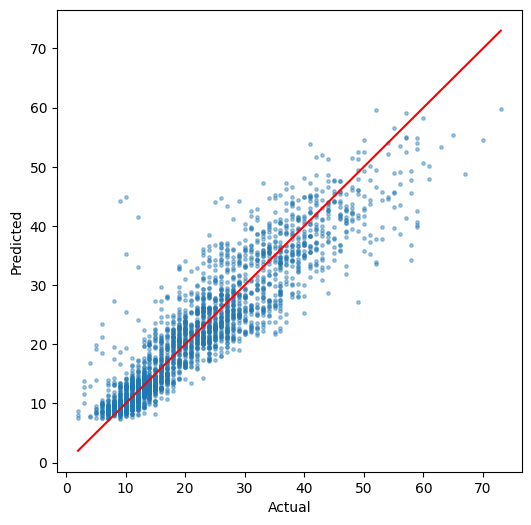

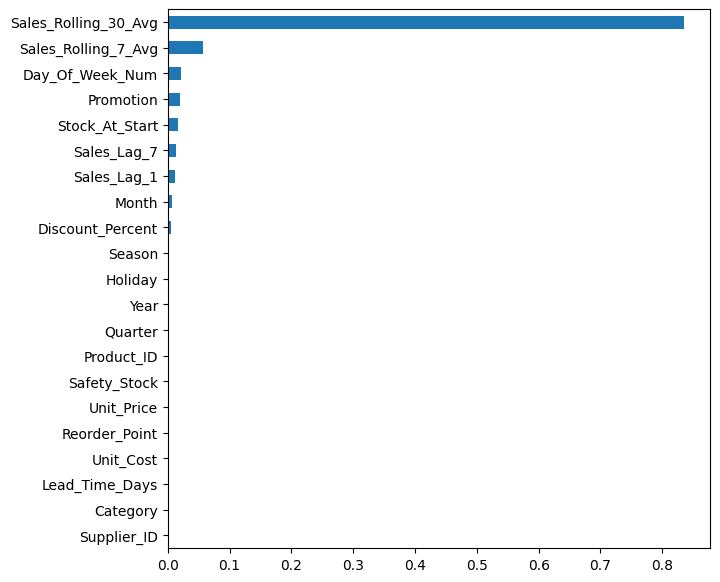

In [61]:
y1pred=rfr.predict(x1test)
plt.figure(figsize=(6,6))
plt.scatter(y1test,y1pred,s=6,alpha=0.4)
plt.plot([y1test.min(),y1test.max()],[y1test.min(),y1test.max()],"r")
plt.xlabel("Actual");plt.ylabel("Predicted");plt.show()

pd.Series(rfr.feature_importances_,index=x1train.columns).sort_values().plot(kind="barh",figsize=(7,7))
plt.show()